In [31]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import time

RANDOM_SEED = 42
# Set the random seed for reproducibility
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [32]:

# The 10 Categories in the CIFAR-10 Dataset
classes = ["Airplane", "Automobile (car)", "Bird", "Cat", "Deer", "Dog", "Frog", "Horse", "Ship", "Truck"]

In [33]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

BATCH_SIZE = 64
# Set the batch size for the DataLoader
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
trainloader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)
testloader = DataLoader(testset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Number of training samples: {len(trainset)}")
print(f"Number of test samples: {len(testset)}")




Number of training samples: 50000
Number of test samples: 10000


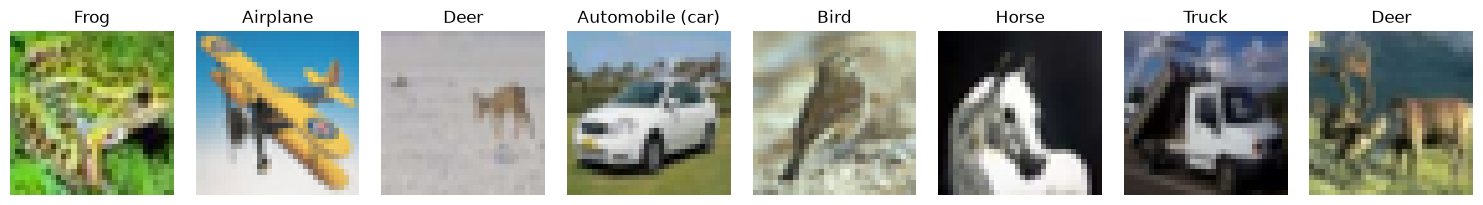

In [34]:
#Example of loading and displaying a batch of CIFAR-10 images
def show_images(images, labels):
    images = images[:8].cpu() * 0.5 + 0.5
    labels = labels[:8].cpu()
    
    figure, axes = plt.subplots(1, 8, figsize=(15, 2))
    for axis, image, label in zip(axes.flat, images, labels):
        axis.imshow(image.permute(1, 2, 0).clamp(0, 1))
        axis.set_title(classes[label.item()])
        axis.axis('off')
    
    figure.tight_layout()
    plt.show()
    
sampleimages, samplelabels = next(iter(trainloader))
show_images(sampleimages, samplelabels)

In [35]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Convolutional Neural Network for CIFAR-10
        self.features = nn.Sequential(
            # Low Level features: input 3x32x32 -> 32x32x32 -> pooled to 32x16x16
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Combinations of edges: 32x16x16 -> 64x16x16 -> pooled to 64x8x8
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Higher Level parts: 64x8x8 -> 128x8x8 -> pooled to 128x4x4
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),
        )

        # Classifier: turns the 128*4*4 = 2048 features into 10 class scores
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.5),          # regularization
            nn.Linear(256, 10),       # output layer (one score per class)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CIFAR10CNN().to(device)
print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 620,362


CNN Model Architecture
The CIFAR-10 CNN uses three convolutional blocks to extract visual features and classify each image.

Convolutional layers: Learn features ranging from edges and color patterns to more complex shapes.
ReLU activation: Adds non-linearity so the network can learn complex patterns.
Max pooling: Reduces feature-map dimensions while keeping important information.
Flattening: Converts the extracted features into a one-dimensional vector.
Fully connected layer: Uses those features to identify the most likely image category.
Output layer: Produces one score for each of the 10 CIFAR-10 classes.

In [36]:
# Loss function for multi-class classification
criterion = nn.CrossEntropyLoss()

# Adam optimizer with a learning rate of 0.001
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: Adam")
print("Learning Rate: 0.001")

Loss Function: CrossEntropyLoss
Optimizer: Adam
Learning Rate: 0.001


In [37]:
# Number of times to train over the dataset
EPOCHS = 5

# Track the average training loss for each epoch
training_losses = []

start_time = time.time()

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for images, labels in trainloader:
        # Move the batch to the selected device
        images = images.to(device)
        labels = labels.to(device)

        # Clear gradients, make predictions, and calculate the loss
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Calculate gradients and update the model weights
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    # Record and display the average loss for the epoch
    epoch_loss = running_loss / len(trainloader)
    training_losses.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{EPOCHS}], Loss: {epoch_loss:.4f}")

end_time = time.time()
print(f"\nTraining completed in {end_time - start_time:.2f} seconds.")

Epoch [1/5], Loss: 1.5348
Epoch [2/5], Loss: 1.1465
Epoch [3/5], Loss: 0.9544
Epoch [4/5], Loss: 0.8334
Epoch [5/5], Loss: 0.7509

Training completed in 611.77 seconds.


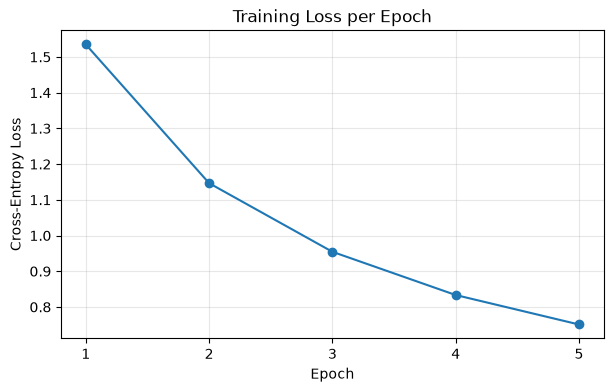

In [38]:
# Plot the average training loss for each epoch
plt.figure(figsize=(7, 4))
plt.plot(range(1, EPOCHS + 1), training_losses, marker="o")

plt.title("Training Loss per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True, alpha=0.3)

plt.show()